# Phase-space tomography with CNN
- Use phase-space distributions with two Gaussian beam components.

Copyright (C) 2024 Hirokazu Maesaka, RIKEN SPring-8 Center. All rights reserved.

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

## Import modules

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde, gamma, norm, multivariate_normal
import math
import matplotlib.pyplot as plt
%matplotlib inline

## Parameters

In [ ]:
N = 10000   # number of data samples
M = 10000   # number of particles
nbins = 100 # number of bins
xmin = -20.0  # x minimum [mm]
xmax =  20.0  # x maximum [mm]
xpmin = -5.0  # x' minimum [mrad]
xpmax =  5.0  # x' maximum [mrad]

## Generate emittance, Twiss parameters, beam centers, randomly

### Distribution of emittance
- Gamma distribution
- natual emittance ~ 1 $\mu$ m

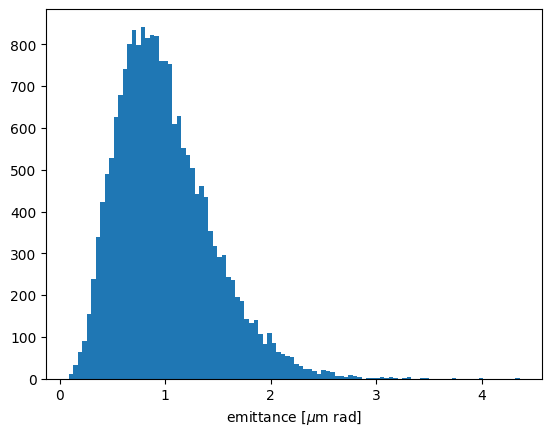

8.565764762347808e-08 1.00138648524443e-06


In [ ]:
gammarv = gamma(a=5, scale=2.0e-7)
emittance = gammarv.rvs(size=N*2).reshape(N,2)
fig, ax = plt.subplots()
y,x,h = ax.hist(emittance.reshape(N*2)*1.0e6, bins=100)
ax.set_xlabel("emittance [$\mu$m rad]")
plt.show()
print(emittance.min(), emittance.mean())

### Distribution of beta
- Gamma distribution
- beta ~ 10 m

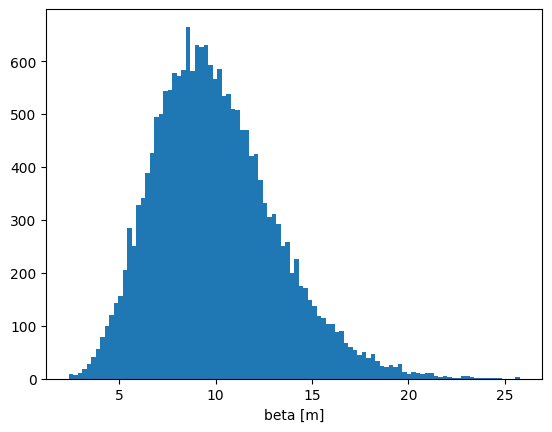

2.3746201327356613 9.996611330357258


In [ ]:
gammarv = gamma(a=10, scale=1.0)
beta = gammarv.rvs(size=N*2).reshape(N,2)
fig, ax = plt.subplots()
y,x,h = ax.hist(beta.reshape(N*2), bins=100)
ax.set_xlabel("beta [m]")
plt.show()
print(beta.min(), beta.mean())

### Distribution of alpha
- Gaussian

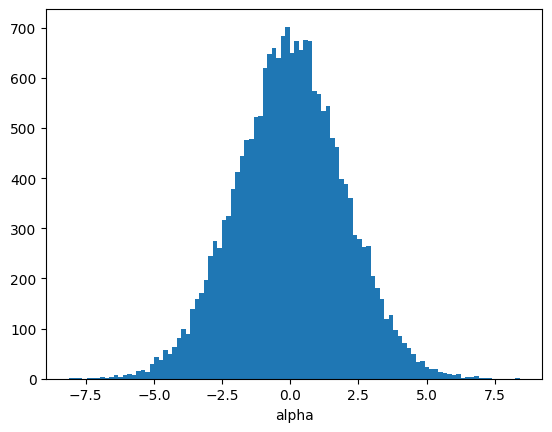

In [ ]:
normrv = norm(loc=0.0, scale=2.0)
alpha = normrv.rvs(size=N*2).reshape(N,2)
fig, ax = plt.subplots()
y,x,h = ax.hist(alpha.reshape(N*2), bins=100)
ax.set_xlabel("alpha")
plt.show()

### Distribution of beam center
- 2D Gaussian

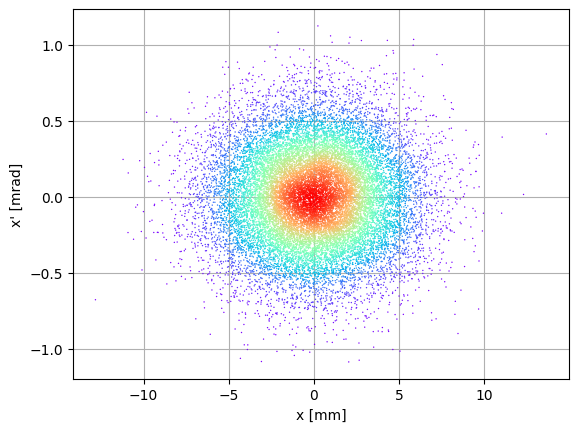

In [ ]:
sig_x = 3.0e-3  # [m]
sig_xp = 3.0e-4  # [m]
mnormrv = multivariate_normal(mean=np.zeros(2), cov=np.diag([sig_x**2, sig_xp**2]))
center = mnormrv.rvs(size=N*2).reshape(N,2,2)
z = gaussian_kde(center.reshape(N*2,2).T)(center.reshape(N*2,2).T)
idx = z.argsort()
z2 = z[idx]
fig, ax = plt.subplots()
ax.scatter(center.reshape(N*2,2)[idx,0]*1.0e3, center.reshape(N*2,2)[idx,1]*1.0e3, c=z2, s=1, cmap='rainbow', edgecolor='none')
ax.grid()
ax.set_axisbelow(True)
ax.set_xlabel("x [mm]")
ax.set_ylabel("x' [mrad]")
plt.show()

## Generate particles

### Calculate covariance matrix

In [ ]:
gam = (1+alpha**2)/beta
cov = np.swapaxes(np.swapaxes(emittance * np.array([[beta, -alpha],[-alpha, gam]]), 0, 2), 1, 3)

### Generate particles
- Each data has two Gaussian components

In [ ]:
particles = np.empty((N,M,2))
for i in range(N):
    particles[i,:M//2,:] = multivariate_normal.rvs(mean=center[i,0], cov=cov[i,0,:,:], size=M//2) * 1.0e3
    particles[i,M//2:,:] = multivariate_normal.rvs(mean=center[i,1], cov=cov[i,1,:,:], size=M//2) * 1.0e3

### Calculate 2D phase-space histogram

In [ ]:
phasespace = np.empty((N,nbins,nbins))
for i in range(N):
    h, x, y = np.histogram2d(particles[i,:,0], particles[i,:,1], bins=(nbins,nbins), range=((xmin,xmax),(xpmin,xpmax)))
    phasespace[i,:,:] = h / np.max(h)
xedges = x
yedges = y

### Check phase-space distribution

0 [2.42718116e-06 1.33962238e-06] [-3.78196779 -2.81852261] [9.83745617 6.85231982] [-0.34985119  0.17759367]


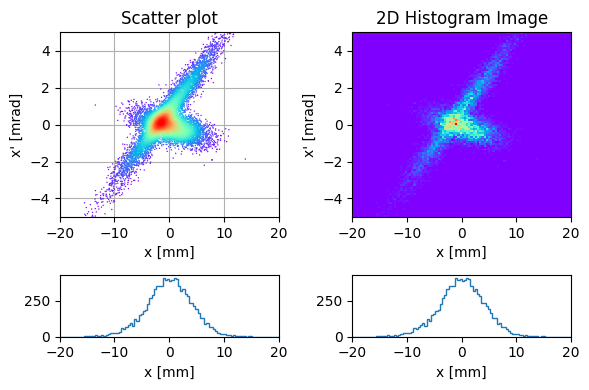

1 [1.05357773e-06 6.06462683e-07] [ 2.38521578 -0.89254499] [13.01997321 -4.14371782] [-1.91488422  0.96765911]


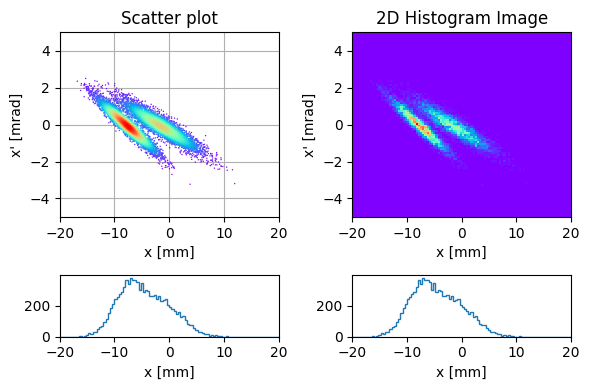

2 [1.14508969e-06 8.19932102e-07] [ 2.09093663 -0.56643736] [13.24484922 -2.920132  ] [1.11697861 0.41418961]


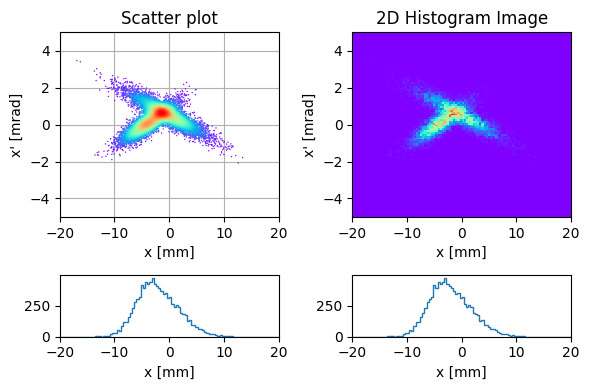

3 [1.44171743e-06 6.65435969e-07] [ 0.48657584 -0.26530173] [10.09991785 -1.05420341] [-1.30944082  1.21784877]


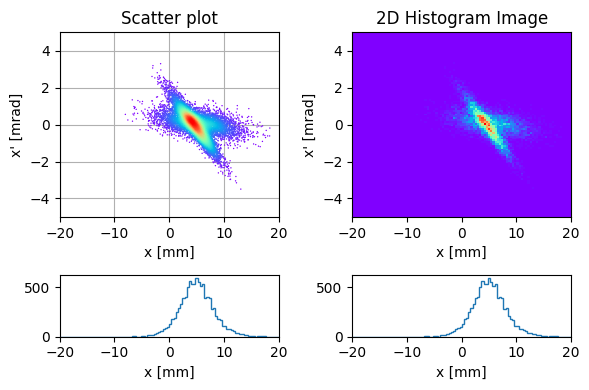

4 [1.48291303e-06 1.57879915e-06] [-2.23435171 -0.45790182] [12.29170068  2.09865154] [-0.21701184  0.0794686 ]


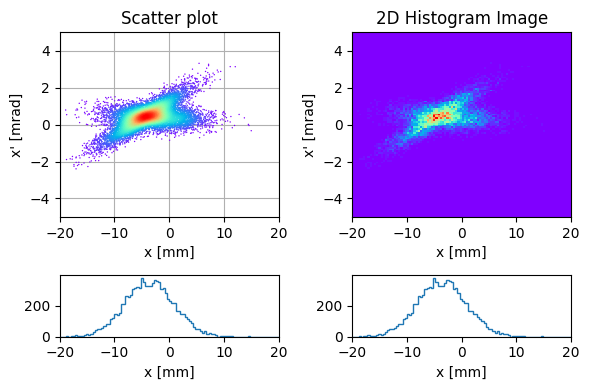

5 [1.53363158e-06 1.15016739e-06] [-1.44040264 -0.37734161] [10.86516901  1.92063086] [-1.19913147  0.24064732]


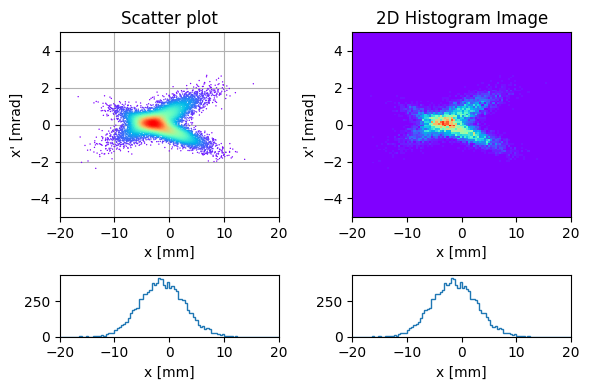

6 [6.85022371e-07 6.41044182e-07] [ 0.41062212 -0.09219269] [13.54534567 -0.43879244] [1.39108816 0.25822225]


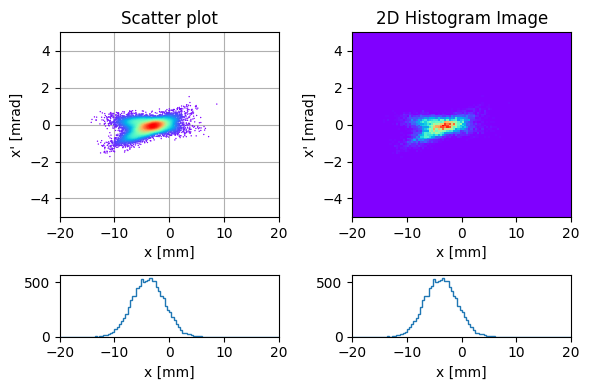

7 [9.76913861e-07 1.21917406e-06] [-0.52325775 -0.08826171] [11.56429049  0.41928201] [-1.25427547  0.15422855]


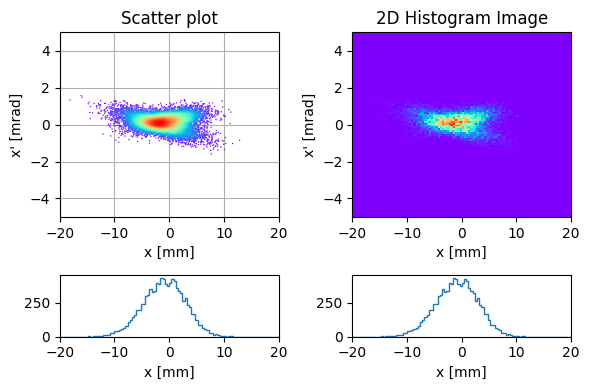

8 [1.17052425e-06 7.53250581e-07] [-5.0686481  -3.42158931] [12.12218908  7.87649641] [1.00805675 0.34765537]


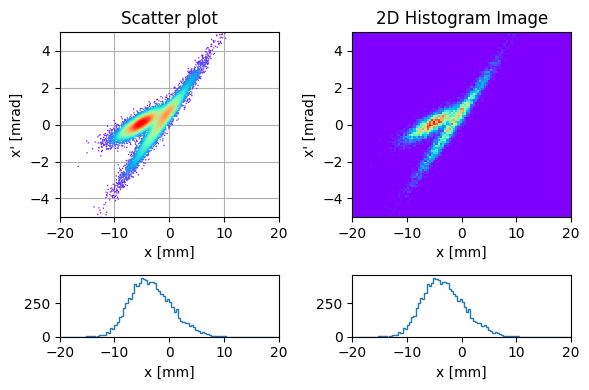

9 [1.19275559e-06 1.85319052e-06] [ 0.78774856 -0.10607442] [ 9.8329219 -0.5070129] [-3.53337799  0.38615338]


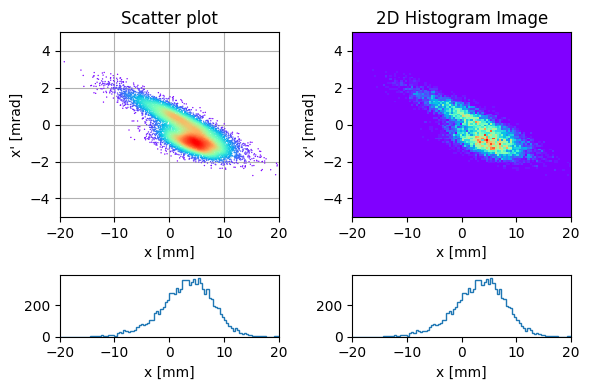

In [ ]:
for i in range(10):
    eps = np.sqrt(np.linalg.det(cov[i,:,:]))
    a = -cov[i,0,1]/eps
    b = cov[i,0,0]/eps
    g = cov[i,1,1]/eps
    print(i, eps, a, b, g)
    data = particles[i,:,:]
    z = gaussian_kde(data.T)(data.T)
    idx = z.argsort()
    z2 = z[idx]
    fig, ax = plt.subplots(2,2,figsize=(6,4), gridspec_kw={'height_ratios': [3,1]})
    ax[0,0].scatter(data[idx,0], data[idx,1], c=z2, s=1, cmap='rainbow', edgecolor='none')
    ax[0,0].grid()
    ax[0,0].set_axisbelow(True)
    ax[0,0].set_xlim((xmin,xmax))
    ax[0,0].set_ylim((xpmin,xpmax))
    ax[0,0].set_xlabel("x [mm]")
    ax[0,0].set_ylabel("x' [mrad]")
    ax[0,0].set_title("Scatter plot")
    y,x,h = ax[1,0].hist(particles[i,:,0], bins=nbins, range=(xmin,xmax), histtype='step')
    ax[1,0].set_xlabel("x [mm]")
    ax[1,0].set_xlim((xmin,xmax))
    ax[0,1].pcolormesh(xedges, yedges, phasespace[i,:,:].T, cmap='rainbow')
    ax[0,1].set_xlabel("x [mm]")
    ax[0,1].set_ylabel("x' [mrad]")
    ax[0,1].set_title("2D Histogram Image")
    y,x,h = ax[1,1].hist(particles[i,:,0], bins=nbins, range=(xmin,xmax), histtype='step')
    ax[1,1].set_xlabel("x [mm]")
    ax[1,1].set_xlim((xmin,xmax))
    plt.tight_layout()
    plt.show()

## Generate tomography data

### Transfer matorices for phase-space rotation

In [ ]:
def matrot(theta, scale):
    mscale = np.array([[1./scale, 0],[0, scale]])
    mrot = np.array([[np.cos(theta), -np.sin(theta)],[np.sin(theta), np.cos(theta)]])
    return np.linalg.inv(mscale) @ mrot @ mscale

### Check rotated phase-space distribution

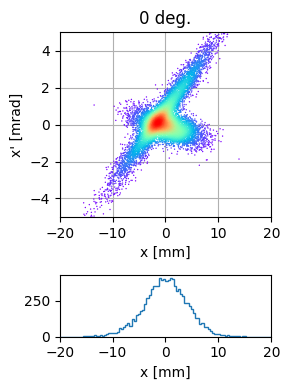

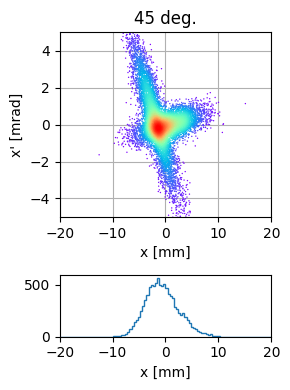

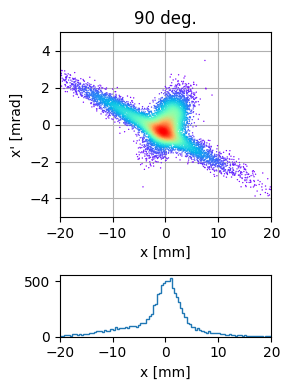

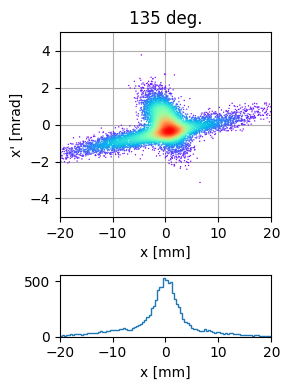

In [ ]:
scale = 2.
for i in range(4):
    theta = np.pi*0.25*i
    mat = matrot(theta, scale)
    rotdata = mat @ particles[0,:,:].T
    x = rotdata[0,:]
    y = rotdata[1,:]
    xy = np.vstack([x,y])
    z = gaussian_kde(xy)(xy)
    idx = z.argsort()
    x2, y2, z2 = x[idx], y[idx], z[idx]
    fig, ax = plt.subplots(2, 1, figsize=(3,4), gridspec_kw={'height_ratios': [3,1]})
    # scatter
    ax[0].scatter(x2, y2, c=z2, s=1, cmap='rainbow', edgecolor='none')
    ax[0].set_xlabel("x [mm]")
    ax[0].set_ylabel("x' [mrad]")
    ax[0].set_title(f"{i*45} deg.")
    ax[0].grid()
    ax[0].set_axisbelow(True)
    ax[0].set_xlim((xmin,xmax))
    ax[0].set_ylim((xpmin,xpmax))
    # x projection
    y,x,p = ax[1].hist(rotdata[0,:], bins=nbins, range=(xmin,xmax), histtype='step')
    ax[1].set_xlabel("x [mm]")
    ax[1].set_xlim((xmin,xmax))
    plt.tight_layout()
    plt.show()
    del rotdata,x,y,xy,z,idx,x2,y2,z2,fig,ax

### Calculate tomography data

In [ ]:
scale = 2.
angles = np.deg2rad(np.arange(0.,180.,2.)) # 2-deg step
tomodata = np.empty((N,len(angles),nbins))
for i,theta in enumerate(angles):
    if i%5 == 0:
        print(np.round(np.rad2deg(theta)))
    mat = matrot(theta, scale)
    rotdata = np.swapaxes(mat @ np.swapaxes(particles, 1, 2), 1, 2)
    for j in range(N):
        val, edge = np.histogram(rotdata[j,:,0], nbins, (xmin,xmax))
        tomodata[j,i,:] = val / M
    del rotdata
print("Done.")
for i in range(N):
    tomodata[i,:,:] /= np.max(tomodata[i,:,:])
print("Normalization done.")

0.0
10.0
20.0
30.0
40.0
50.0
60.0
70.0
80.0
90.0
100.0
110.0
120.0
130.0
140.0
150.0
160.0
170.0
Done.
Normalization done.


### Check generated images

0


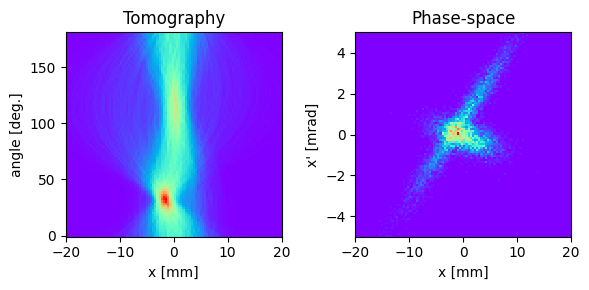

1.0
1


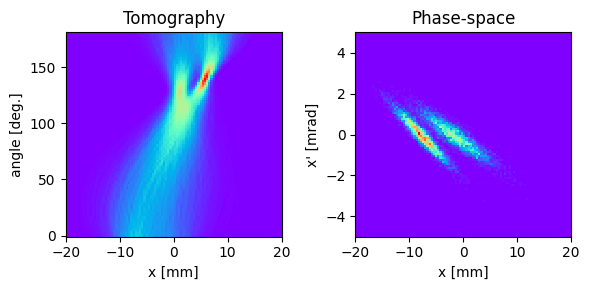

1.0
2


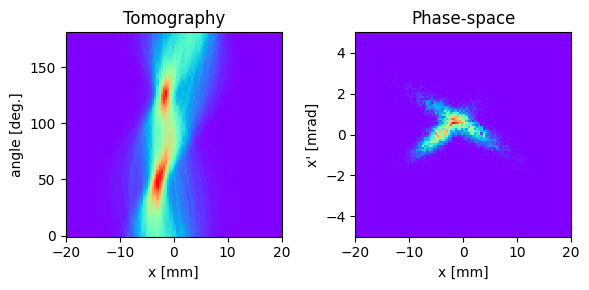

1.0
3


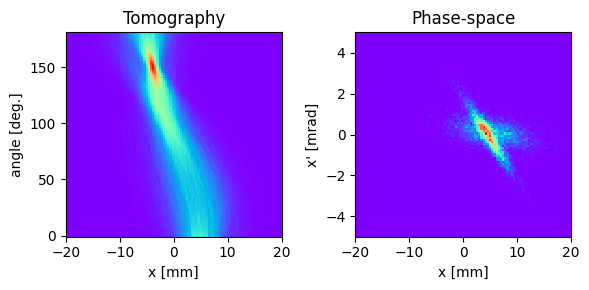

1.0
4


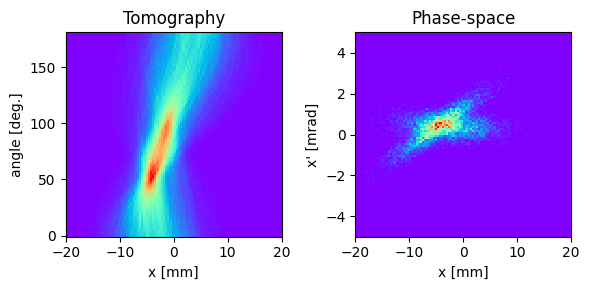

1.0
5


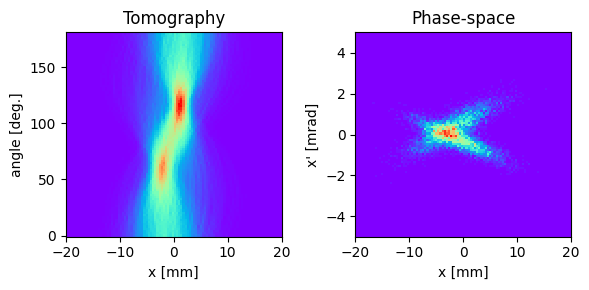

1.0
6


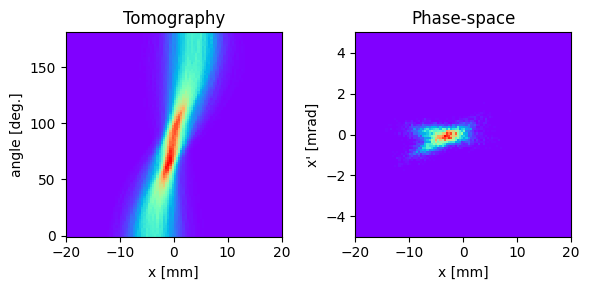

1.0
7


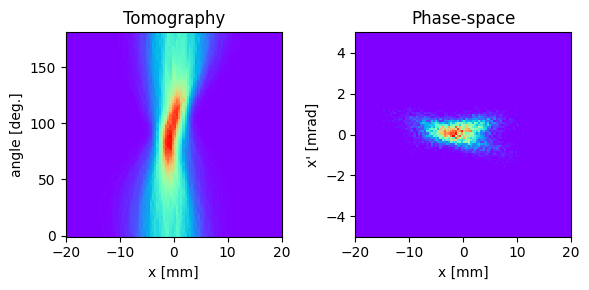

1.0
8


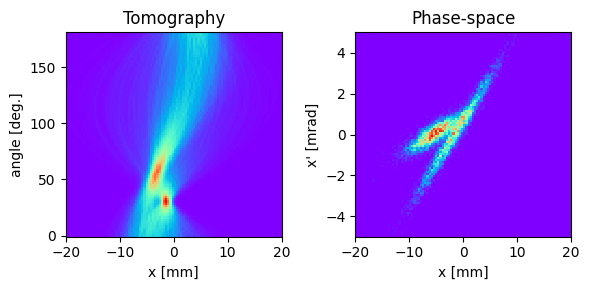

1.0
9


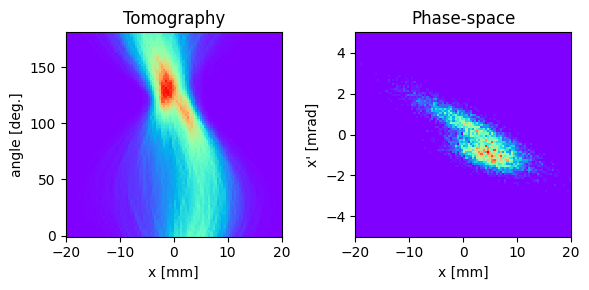

1.0


In [ ]:
for i in range(10):
    print(i)
    fig, ax = plt.subplots(1, 2, figsize=(6,3))
    ax[0].pcolormesh(np.linspace(xmin,xmax,nbins+1), np.linspace(-1.,181.,91), tomodata[i,:,:], cmap='rainbow')
    ax[0].set_xlabel("x [mm]")
    ax[0].set_ylabel("angle [deg.]")
    ax[0].set_title("Tomography")
    ax[1].pcolormesh(xedges, yedges, phasespace[i,:,:].T, cmap='rainbow')
    ax[1].set_xlabel("x [mm]")
    ax[1].set_ylabel("x' [mrad]")
    ax[1].set_xlim((xmin,xmax))
    ax[1].set_ylim((xpmin,xpmax))
    ax[1].set_title("Phase-space")
    plt.tight_layout()
    plt.show()
    print(np.max(tomodata[i,:,:]))

## Prepare data for CNN

### Split data into training, test, and validation

In [ ]:
n_train, n_test, n_val = 6000, 2000, 2000
x_train, y_train = tomodata[:n_train,:,:], phasespace[:n_train,:]
x_test, y_test = tomodata[n_train:n_train+n_test,:,:], phasespace[n_train:n_train+n_test,:]
x_val, y_val = tomodata[-n_val:,:,:], phasespace[-n_val:,:]

### Input and output image dimensions

In [ ]:
input_shape = (len(angles), nbins, 1)
output_shape = (nbins, nbins, 1)

### Reshape data

In [ ]:
x_train1 = x_train.reshape(x_train.shape[0], input_shape[0], input_shape[1], input_shape[2]).astype(np.float32)
x_test1 = x_test.reshape(x_test.shape[0], input_shape[0], input_shape[1], input_shape[2]).astype(np.float32)
x_val1 = x_val.reshape(x_val.shape[0], input_shape[0], input_shape[1], input_shape[2]).astype(np.float32)
y_train1 = y_train.reshape(y_train.shape[0], output_shape[0], output_shape[1], output_shape[2]).astype(np.float32)
y_test1 = y_test.reshape(y_test.shape[0], output_shape[0], output_shape[1], output_shape[2]).astype(np.float32)
y_val1 = y_val.reshape(y_val.shape[0], output_shape[0], output_shape[1], output_shape[2]).astype(np.float32)

## Training of CNN

### Import modules

In [ ]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout, Flatten, Reshape
from keras.layers import Conv2D, MaxPooling2D, UpSampling2D
from keras import backend as K

batch_size = 128
#epochs = 1000
epochs = 100

### Make CNN model

In [ ]:
model = Sequential()
model.add(Input(input_shape))
model.add(Conv2D(32, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(10, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dense(25*25, activation='relu'))
model.add(Reshape((25,25,1)))
model.add(Conv2D(10, kernel_size=(3,3), activation='relu', padding='same'))
model.add(UpSampling2D((2,2)))
model.add(Conv2D(32, kernel_size=(3,3), activation='relu', padding='same'))
model.add(UpSampling2D((2,2)))
model.add(Conv2D(1, kernel_size=(3,3), activation='sigmoid', padding='same'))
model.compile(loss='binary_crossentropy', optimizer='adam')

### Check model

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 88, 98, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 44, 49, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 42, 47, 10)          │           2,890 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 21, 23, 10)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4830)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │       1,236,736 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 625)                 │         160,625 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape (Reshape)                    │ (None, 25, 25, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 25, 25, 10)          │             100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d (UpSampling2D)         │ (None, 50, 50, 10)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 50, 50, 32)          │           2,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_1 (UpSampling2D)       │ (None, 100, 100, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 100, 100, 1)         │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,403,872 (5.36 MB)

 Trainable params: 1,403,872 (5.36 MB)

 Non-trainable params: 0 (0.00 B)

### Fit the model to data

In [ ]:
history = model.fit(x_train1, y_train1, batch_size=2*batch_size, epochs=epochs, verbose=1, validation_data=(x_test1, y_test1))
score = model.evaluate(x_test1, y_test1, verbose=0)
print('Test loss:', score)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 475ms/step - loss: 0.5091 - val_loss: 0.0695
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - loss: 0.0626 - val_loss: 0.0546
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - loss: 0.0527 - val_loss: 0.0519
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - loss: 0.0506 - val_loss: 0.0504
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 0.0493 - val_loss: 0.0491
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step - loss: 0.0481 - val_loss: 0.0478
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.0465 - val_loss: 0.0466
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - loss: 0.0454 - val_loss: 0.0451
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.0435 - val_loss: 0.0435
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.0422 - val_loss: 0.0419
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step - loss: 0.0412 - val_loss: 0.0406
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/st

### Evolution of loss function

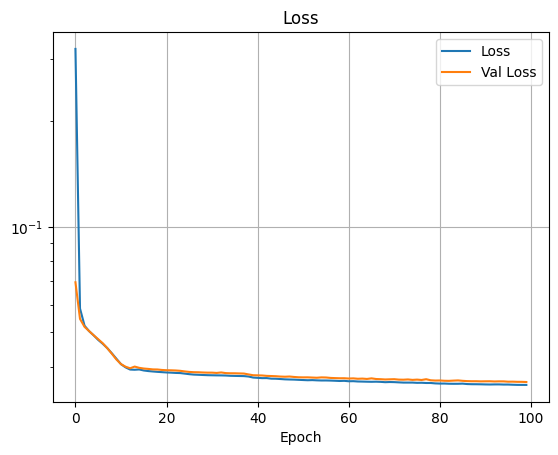

In [ ]:
fig, ax = plt.subplots()
ax.semilogy(history.history['loss'], label='Loss')
ax.semilogy(history.history['val_loss'], label='Val Loss')
ax.set_title('Loss')
ax.set_xlabel('Epoch')
ax.grid()
ax.legend()
plt.show()

### Spot check of phase-space distribution

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


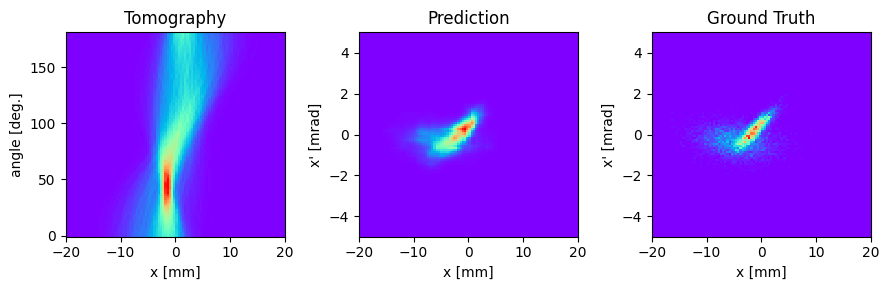

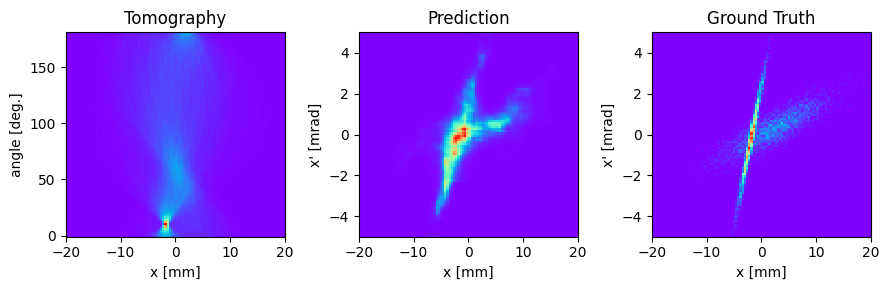

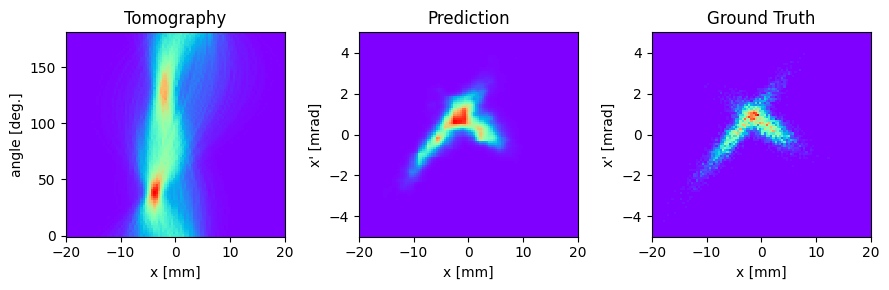

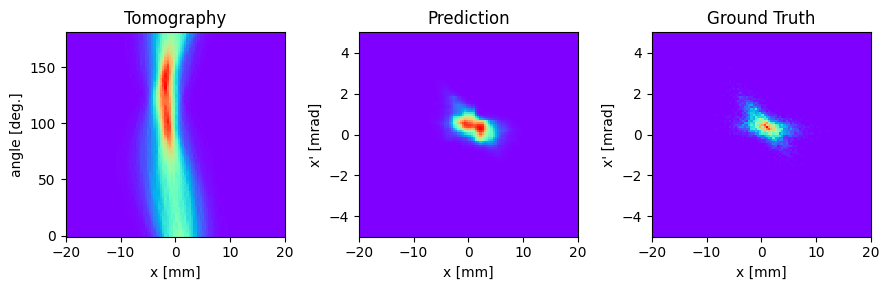

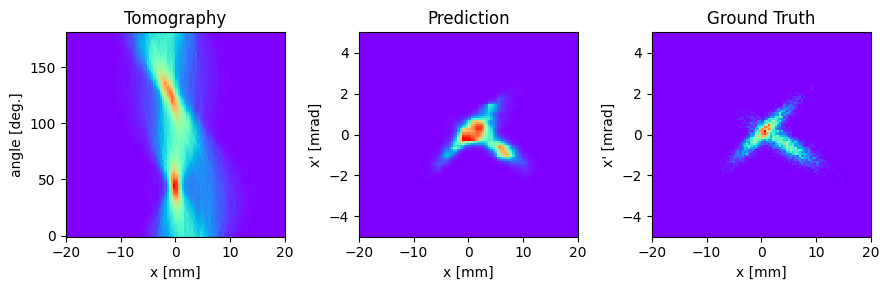

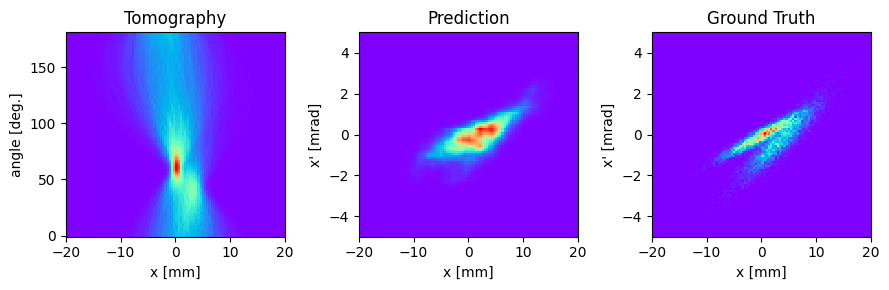

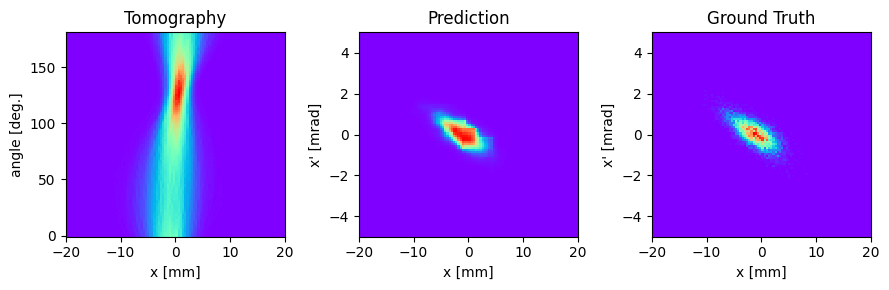

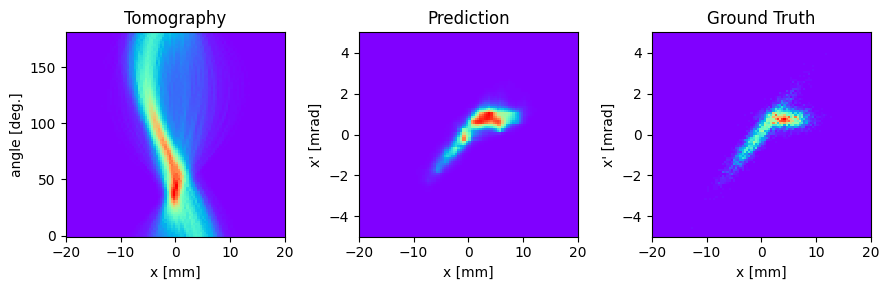

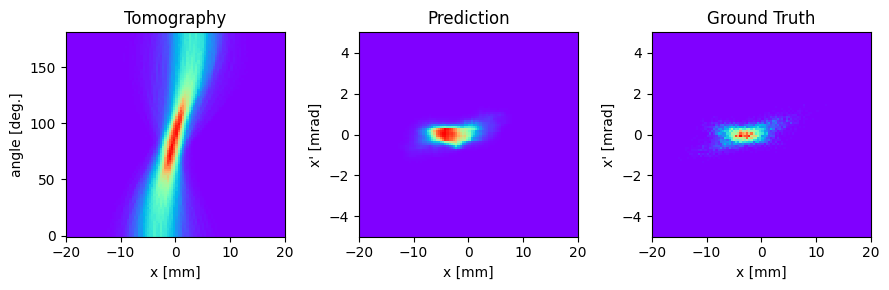

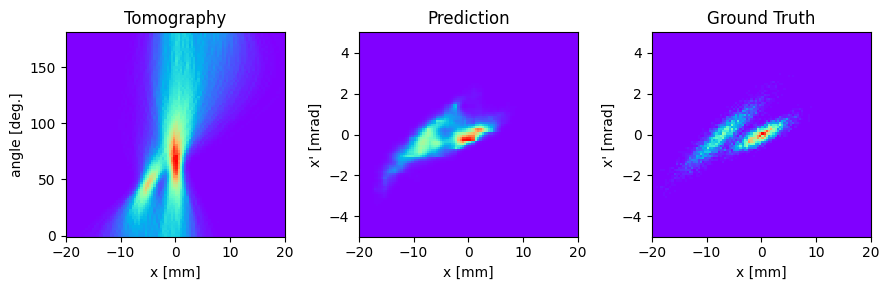

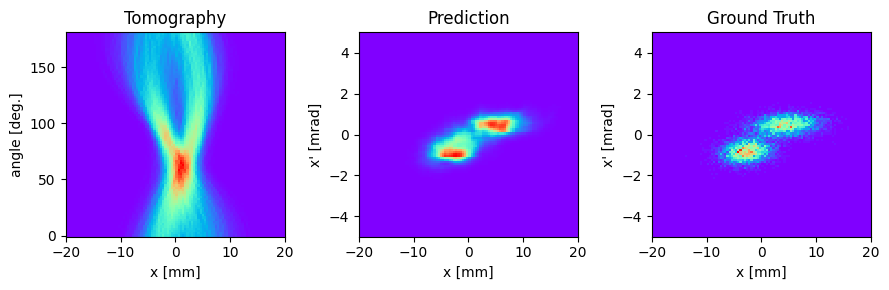

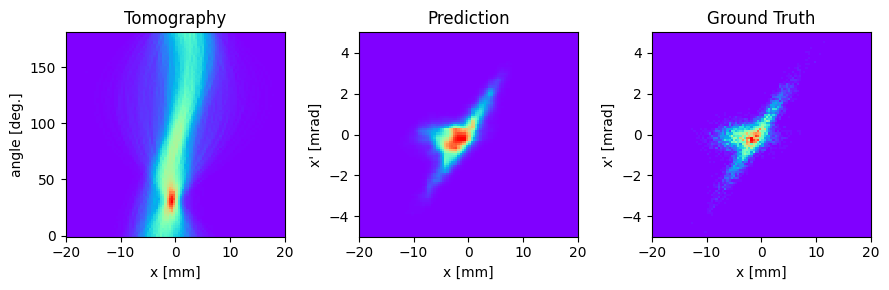

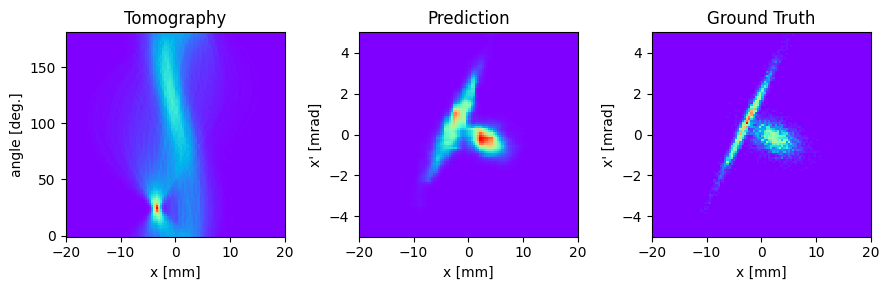

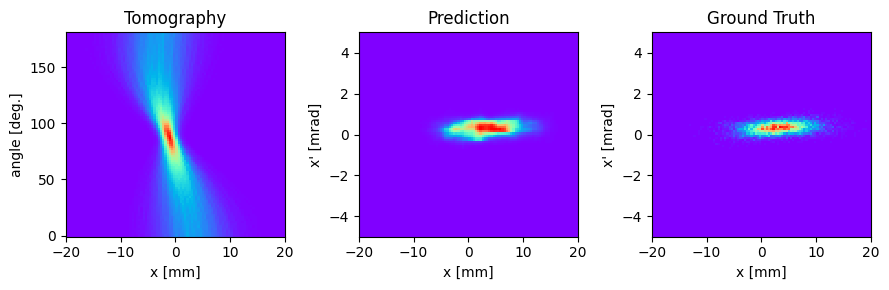

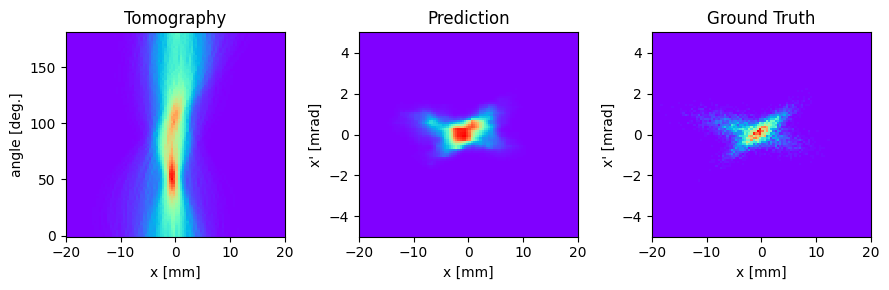

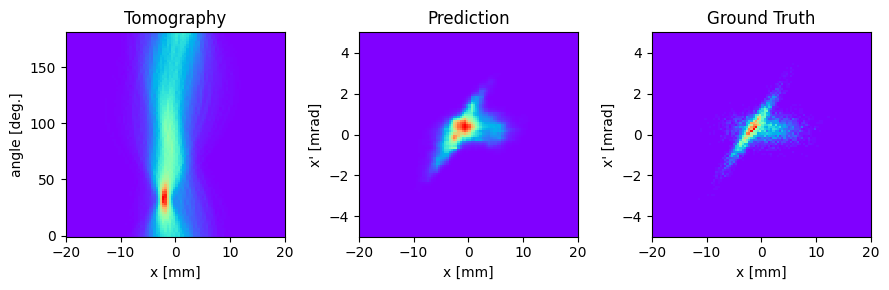

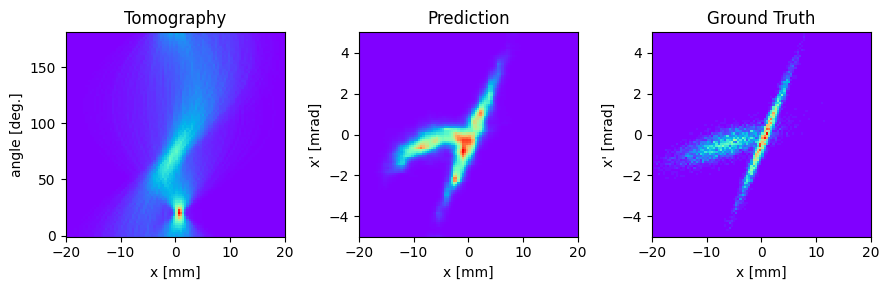

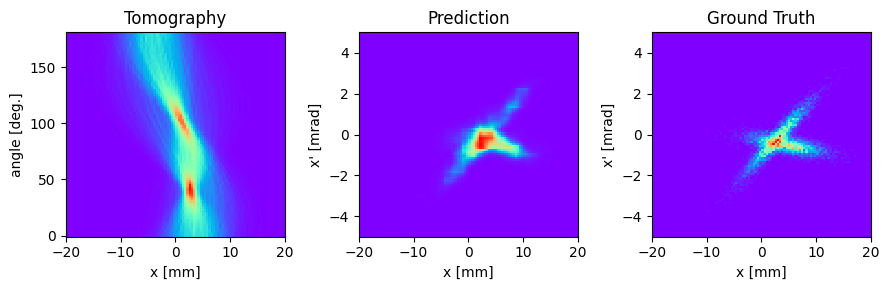

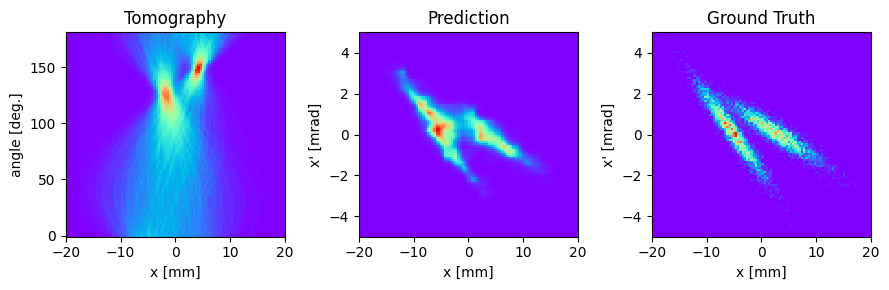

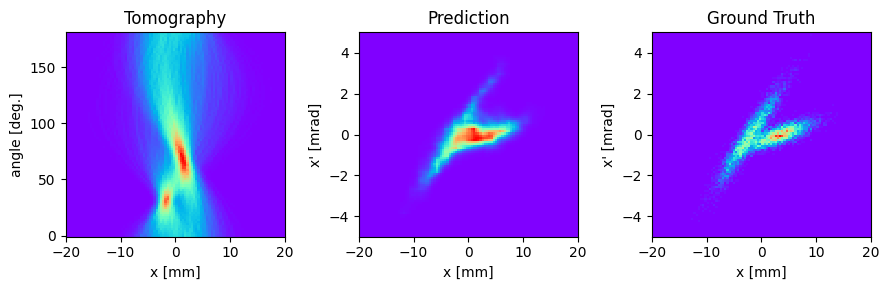

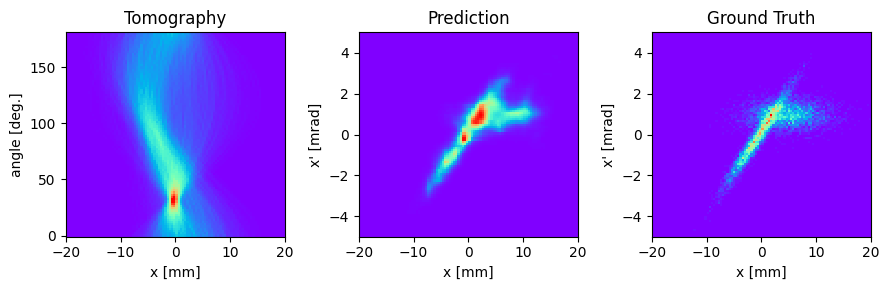

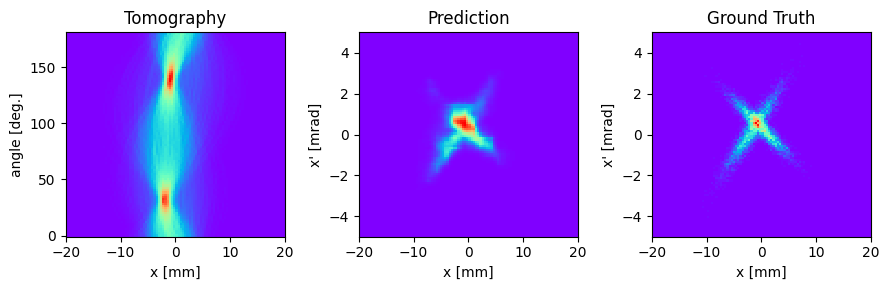

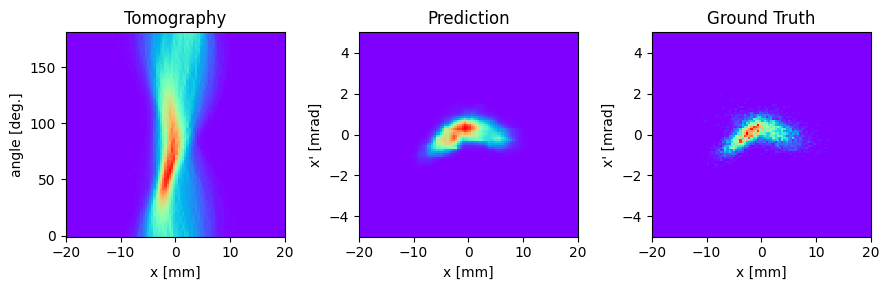

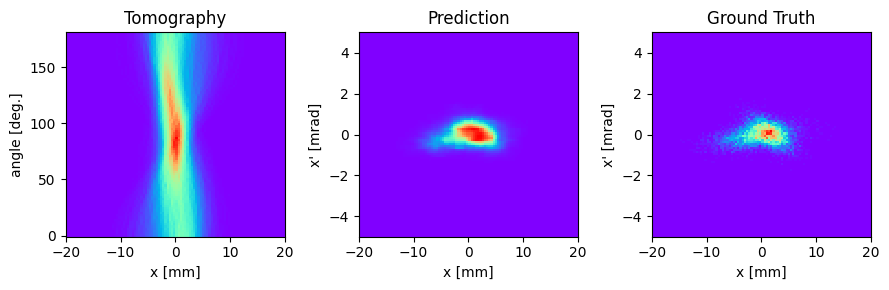

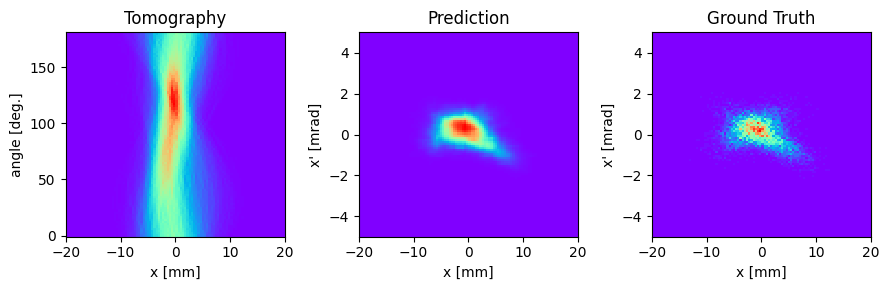

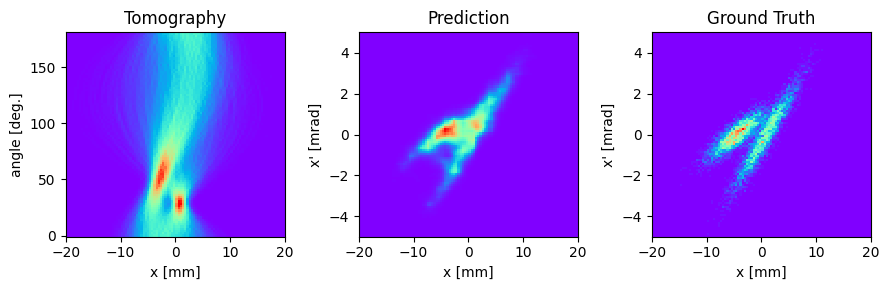

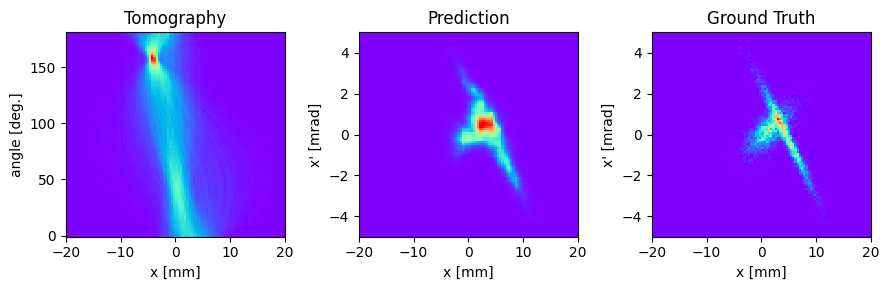

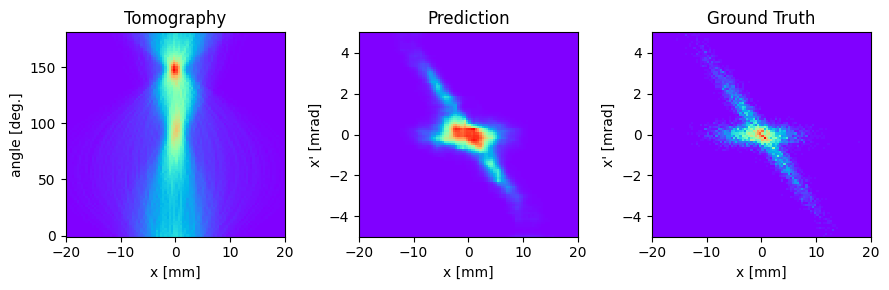

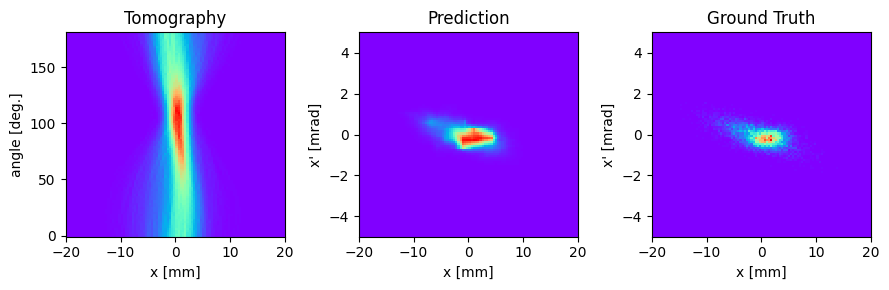

In [ ]:
predictions = model.predict(x_val1)
for i in range(30):
    fig, ax = plt.subplots(1, 3, figsize=(9,3))
    ax[0].pcolormesh(np.linspace(xmin,xmax,nbins+1), np.linspace(-1.,181.,91), tomodata[n_train+n_test+i,:,:], cmap='rainbow')
    ax[0].set_xlabel("x [mm]")
    ax[0].set_ylabel("angle [deg.]")
    ax[0].set_title("Tomography")
    ax[1].pcolormesh(xedges, yedges, predictions[i,:,:,0].T, cmap='rainbow')
    ax[1].set_xlim((xmin,xmax))
    ax[1].set_ylim((xpmin,xpmax))
    ax[1].set_xlabel("x [mm]")
    ax[1].set_ylabel("x' [mrad]")
    ax[1].set_title("Prediction")
    ax[2].pcolormesh(xedges, yedges, phasespace[n_train+n_test+i,:,:].T, cmap='rainbow')
    ax[2].set_xlim((xmin,xmax))
    ax[2].set_ylim((xpmin,xpmax))
    ax[2].set_xlabel("x [mm]")
    ax[2].set_ylabel("x' [mrad]")
    ax[2].set_title("Ground Truth")
    plt.tight_layout()
    plt.show()